# Identify cytotoxic treatments

**Question:** which treatments kill cells or stop their growth?

We count the cells in each well from the single-cell profiles and compare every treatment with the DMSO wells of the same plate and cell line. A treatment is **cytotoxic** when its cell count falls more than a set number of standard deviations (SD) below DMSO.


In [4]:
import os

# limit threads, because this can run on a shared login node
os.environ["POLARS_MAX_THREADS"] = "8"
os.environ["OMP_NUM_THREADS"] = "8"
os.environ["OPENBLAS_NUM_THREADS"] = "8"

import pathlib

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

In [5]:
# input: all segmented cells (before QC), with treatment metadata; only a few metadata columns are read
sc_path = pathlib.Path("../2.preprocessing/results/norm_fs_Panc1_hPSC_sc-profiles.parquet").resolve(strict=True)

# outputs
fig_dir = pathlib.Path("results/figures/04.identify-cytotoxic-perts").resolve()
table_dir = pathlib.Path("results/tables/04.identify-cytotoxic-perts").resolve()
fig_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

# a treatment is cytotoxic when the median z-score of its 3 wells is at or below -n_sd
n_sd = 3

# random sets of 3 DMSO wells, used to check how often the rule calls DMSO cytotoxic
n_null_draws = 100_000
seed = 0

# fixed order and colors: the same as in the other notebooks
plate_order = ["1h", "4h", "24h"]
line_order = ["CL1", "CL2"]
compounds = ["CBK041498", "CBK175924", "CBK200566", "CBK600005", "CBK600008"]
treatment_order = ["TGFb1", "IL6", *compounds]
perturbation_order = [f"{t}_{d}" for t in ["TGFb1", "IL6"] for d in ["L", "M", "H"]] + [
    f"{c}_{d}" for c in compounds for d in ["0.2", "0.67", "2.0"]
]
agent_colors = {
    "DMSO": "#a5a5a5", "CBK041498": "#2a78d6", "CBK175924": "#eb6834", "CBK200566": "#1baf7a",
    "CBK600005": "#6250d6", "CBK600008": "#eda100", "IL6": "#d03b3b", "TGFb1": "#0d366b",
}
div_cmap = plt.get_cmap("RdBu_r")

# setting the theme for seaborn and matplotlib
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
rng = np.random.default_rng(seed)


# helper functions for plotting and data manipulation
def save_fig(fig, name):
    """Save a figure as png for the report and show it in the notebook."""
    fig.savefig(fig_dir / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()


def time_sort(df):
    """Sort rows by time point (1h, 4h, 24h), then cell line."""
    return df.sort(pl.col("time_point").cast(pl.Enum(plate_order)), "cell_line")

## 1. Count cells per well

We count every segmented cell per well, before QC: cells that fail QC are still cells in the well. Wells that fail well QC keep their counts too, because a low count is exactly what we look for here.

**Pass if:** 1,140 wells, each with 9 imaged fields of view.

In [7]:
# setting the metadata columns to read from the parquet file
well_keys = ["Metadata_Plate", "Metadata_Well"]
meta_cols = [*well_keys, "Metadata_cell_line", "Metadata_time_point", "Metadata_treatment", "Metadata_Perturbation"]

# lazy scan: only the metadata columns are read, not the features
# assessing cell data only requires the metadata, so this is much faster than reading the entire parquet file
wells = (
    pl.scan_parquet(sc_path)
    .select(*meta_cols, "Metadata_Site")
    .with_columns(pl.col(pl.Categorical).cast(pl.String))
    .group_by(meta_cols)
    .agg(n_cells=pl.len(), n_sites=pl.col("Metadata_Site").n_unique())
    .collect()
    .rename({"Metadata_cell_line": "cell_line", "Metadata_time_point": "time_point", "Metadata_treatment": "treatment"})
    .with_columns(is_dmso=pl.col("treatment") == "DMSO")
    .sort(well_keys)
)

assert wells.height == 1140
print(f"Read {wells.height} wells from {sc_path.name} (only metadata columns).")

Read 1140 wells from norm_fs_Panc1_hPSC_sc-profiles.parquet (only metadata columns).


**Result:** 1,140 wells and 2,647,721 cells; 127 DMSO wells and 21 treatments × 3 wells per plate and cell line. 3 wells have one field of view without cells (24h plate, CL1, inside the low-count area).

## 2. Set the threshold from the DMSO wells

For each plate and cell line, we scale every well to the DMSO median (relative cell count) and measure the robust SD of the DMSO wells. The threshold is the DMSO median minus `n_sd` robust SDs.

We use the median of the 3 replicate wells, so one odd well cannot make a call: a median at or below the threshold means at least 2 of the 3 wells are below it.

To check the threshold, we apply the same rule to 100,000 random sets of 3 DMSO wells. The share that gets called cytotoxic is the false-positive rate per test.

**Pass if:** the false-positive rate is below about 1%, so that fewer than 1 of the 126 treatment tests is expected to be a false call.

In [8]:
# grouping by plate and cell line, then calculating relative counts, robust standard deviation, and z-scores for each well
group_keys = ["Metadata_Plate", "cell_line"]
wells = (
    wells.with_columns(rel_count=pl.col("n_cells") / pl.col("n_cells").filter(pl.col("is_dmso")).median().over(group_keys))
    .with_columns(robust_sd=(1.4826 * (pl.col("rel_count") - 1).abs().filter(pl.col("is_dmso")).median()).over(group_keys))
    .with_columns(z=(pl.col("rel_count") - 1) / pl.col("robust_sd"))
)

# iterating over each plate and cell line, calculating the median z-score of random sets of 3 DMSO wells, 
# and storing the results in a list of dictionaries
dmso_rows = []
for (plate, line), grp in wells.filter(pl.col("is_dmso")).group_by(group_keys, maintain_order=True):
    z = grp["z"].to_numpy()

    # random sets of 3 DMSO wells; the rule calls a set when its median z-score is <= -n_sd
    picks = np.argsort(rng.random((n_null_draws, len(z))), axis=1)[:, :3]
    null_medians = np.median(z[picks], axis=1)
    rsd = grp["robust_sd"][0]

    # store the results in a dictionary and append to the list
    dmso_rows.append(
        {
            "time_point": grp["time_point"][0], "cell_line": line, "n_dmso_wells": len(z),
            "dmso_median_cells": grp["n_cells"].median(),
            "sd_pct": 100 * grp["rel_count"].std(), "robust_sd_pct": 100 * rsd,
            "threshold_pct_of_dmso": 100 * (1 - n_sd * rsd),
            "false_positive_pct": 100 * np.mean(null_medians <= -n_sd),
            "false_positive_pct_at_2sd": 100 * np.mean(null_medians <= -2),
        }
    )

# create a dataframe from the list of dictionaries, sort it by time point and cell line, 
# write it to a CSV file, and print it with specific formatting
dmso_table = time_sort(pl.DataFrame(dmso_rows))
dmso_table.write_csv(table_dir / "dmso_threshold.csv")
with pl.Config(float_precision=2, tbl_width_chars=200):
    print(dmso_table)

# 21 treatments are tested per plate and cell line
expected_false = (21 * dmso_table["false_positive_pct"] / 100).sum()
print(f"expected false calls among the 126 tests at {n_sd} SD: {expected_false:.2f}")

shape: (6, 9)
┌────────────┬───────────┬──────────────┬───────────────────┬───┬───────────────┬───────────────────────┬────────────────────┬───────────────────────────┐
│ time_point ┆ cell_line ┆ n_dmso_wells ┆ dmso_median_cells ┆ … ┆ robust_sd_pct ┆ threshold_pct_of_dmso ┆ false_positive_pct ┆ false_positive_pct_at_2sd │
│ ---        ┆ ---       ┆ ---          ┆ ---               ┆   ┆ ---           ┆ ---                   ┆ ---                ┆ ---                       │
│ str        ┆ str       ┆ i64          ┆ f64               ┆   ┆ f64           ┆ f64                   ┆ f64                ┆ f64                       │
╞════════════╪═══════════╪══════════════╪═══════════════════╪═══╪═══════════════╪═══════════════════════╪════════════════════╪═══════════════════════════╡
│ 1h         ┆ CL1       ┆ 127          ┆ 2300.00           ┆ … ┆ 12.89         ┆ 61.32                 ┆ 0.00               ┆ 0.23                      │
│ 1h         ┆ CL2       ┆ 127          ┆ 1840.00       

**Result:** - The robust SD of DMSO is 7–13% on the 1h and 4h plates and for CL2 at 24h, so the threshold lies at 61–78% of DMSO.
- CL1 at 24h is much noisier (robust SD 22%), because of a low-count area in the plate. Its threshold is 33% of DMSO, so only a strong cell loss is called there.
- At 3 SD the rule calls at most 0.22% of random DMSO sets (0.07 false calls expected in 126 tests): **pass**. At 2 SD it would call up to 2.7% (about 1.6 false calls expected), so we keep 3 SD.

## 3. Call cytotoxic treatments

For each treatment, plate and cell line we take the median relative cell count and the median z-score of its 3 wells, and call it cytotoxic when the median z-score is at or below −`n_sd`.

**Pass if:** the replicate wells of a called treatment agree (all 3 well below DMSO).

In [14]:
# grouping by treatment, cell line, and time point, then calculating the median z-score of the 3 wells for each treatment
calls = (
    wells.filter(~pl.col("is_dmso"))
    .sort("Metadata_Well")
    .group_by("time_point", "cell_line", "treatment", "Metadata_Perturbation")

    # aggregating the number of wells, median relative count, median z-score, 
    # rounded z-scores for each well, and the number of wells below the threshold
    .agg(
        n_wells=pl.len(),
        pct_of_dmso=100 * pl.col("rel_count").median(),
        median_z=pl.col("z").median(),
        well_z=pl.col("z").round(1).cast(pl.String).str.join(", "),
        wells_below=(pl.col("z") <= -n_sd).sum(),
    )
    .with_columns(cytotoxic=pl.col("median_z") <= -n_sd)

    # sorting the results by perturbation, cell line, and time point
    .sort(
        pl.col("Metadata_Perturbation").cast(pl.Enum(perturbation_order)),
        pl.col("cell_line"),
        pl.col("time_point").cast(pl.Enum(plate_order)),
    )
)

# checking that the number of calls is as expected, and writing the results to a CSV file
assert calls.height == 126 and (calls["n_wells"] == 3).all()
calls.write_csv(table_dir / "cytotoxicity_calls.csv")

# printing the number of cytotoxic calls and the total number of tests, along with the robust standard deviation
print(f"cytotoxic: {calls['cytotoxic'].sum()} of {calls.height} treatment x plate x cell line tests ({n_sd} robust SD)")

# display out the called treatments, and near misses down to 2 SD
calls.filter(pl.col("median_z") <= -2).sort("median_z").drop("n_wells", "treatment").head(10)


cytotoxic: 6 of 126 treatment x plate x cell line tests (3 robust SD)


time_point,cell_line,Metadata_Perturbation,pct_of_dmso,median_z,well_z,wells_below,cytotoxic
str,str,str,f64,f64,str,u32,bool
"""24h""","""CL2""","""CBK600005_0.67""",50.235784,-6.111295,"""-6.1, -6.3, -5.7""",3,true
"""24h""","""CL2""","""CBK600005_2.0""",50.568655,-6.070417,"""-5.8, -6.5, -6.1""",3,true
"""24h""","""CL2""","""CBK200566_0.67""",56.865465,-5.297137,"""-4.6, -5.3, -5.7""",3,true
"""24h""","""CL2""","""CBK200566_2.0""",57.142857,-5.263072,"""-4.6, -7.0, -5.3""",3,true
"""24h""","""CL2""","""CBK600005_0.2""",63.633842,-4.465946,"""-3.9, -4.5, -8.1""",3,true
"""24h""","""CL2""","""CBK200566_0.2""",71.151179,-3.54278,"""-3.5, -5.0, -2.5""",2,true
"""24h""","""CL1""","""CBK600005_0.2""",33.477218,-2.988878,"""-2.2, -3.1, -3.0""",1,false
"""4h""","""CL2""","""TGFb1_M""",80.566987,-2.330558,"""-3.7, -2.3, 1.2""",1,false
"""24h""","""CL1""","""CBK600005_0.67""",48.153477,-2.329471,"""-2.3, -2.3, -2.9""",0,false


- 6 of 126 tests are cytotoxic, all in CL2 at 24h: **CBK600005** (64%, 50%, 51% of DMSO at 0.2, 0.67, 2 mM) and **CBK200566** (71%, 57%, 57%). All 3 wells of each are at least 2.5 SD below DMSO: **pass**.
## 4. Heatmap of cell loss

Rows are treatments and doses, columns are cell line and time point. Left: relative cell count (% of DMSO). Right: z-score (robust SDs from DMSO). A black frame marks a cytotoxic call.

In [ ]:
# heatmap of relative cell counts and z-scores for all treatments, with cytotoxic calls highlighted
heat_cols = [(line, tp) for line in line_order for tp in plate_order]


# hlper function for pivoting one treatment-level value into a perturbation x (cell line, time point) matrix
def treatment_matrix(value):
    """Pivot one treatment-level value into a perturbation x (cell line, time point) matrix."""
    mat = np.full((len(perturbation_order), len(heat_cols)), np.nan)
    for r in calls.iter_rows(named=True):
        mat[perturbation_order.index(r["Metadata_Perturbation"]), heat_cols.index((r["cell_line"], r["time_point"]))] = r[value]
    return mat


# creating matrices for the heatmap: percentage of DMSO, median z-scores, and cytotoxic calls
pct_mat = treatment_matrix("pct_of_dmso")
z_mat = treatment_matrix("median_z")
hit_mat = treatment_matrix("cytotoxic").astype(bool)
z_lim = float(np.ceil(np.nanmax(np.abs(z_mat))))

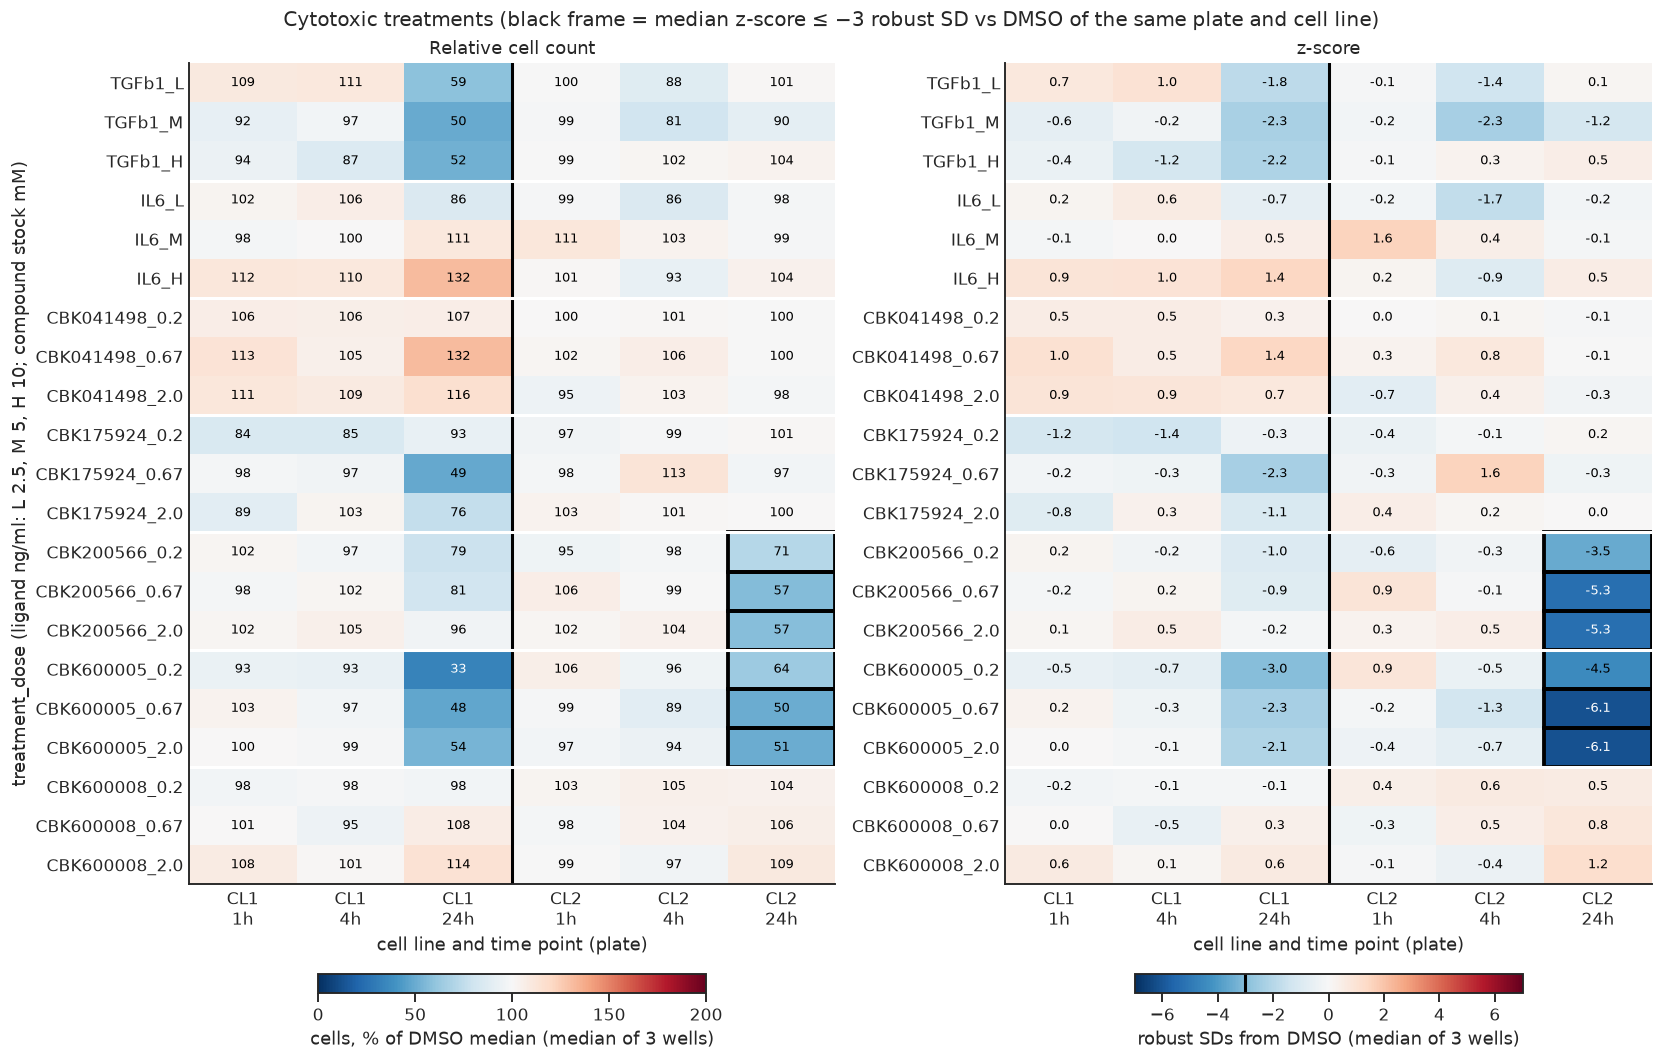

In [ ]:
# creating plot 
fig, axes = plt.subplots(1, 2, figsize=(15, 9.5), layout="constrained")

# setting panels for the heatmap: percentage of DMSO, median z-scores, and cytotoxic calls
panels = [
    (axes[0], pct_mat, TwoSlopeNorm(100, 0, 200), "{:.0f}", "cells, % of DMSO median (median of 3 wells)", "Relative cell count"),
    (axes[1], z_mat, TwoSlopeNorm(0, -z_lim, z_lim), "{:.1f}", "robust SDs from DMSO (median of 3 wells)", "z-score"),
]

# iterating over each panel, plotting the heatmap, adding text annotations, and customizing the axes and colorbars
for ax, mat, norm, fmt, label, title in panels:
    im = ax.imshow(mat, cmap=div_cmap, norm=norm, aspect="auto")
    for (r, c), v in np.ndenumerate(mat):
        ax.text(c, r, fmt.format(v), ha="center", va="center", fontsize=8.5, color="white" if abs(norm(v) - 0.5) > 0.33 else "black")
        if hit_mat[r, c]:
            ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor="black", lw=2.5))
    ax.set_xticks(range(len(heat_cols)), labels=[f"{line}\n{tp}" for line, tp in heat_cols])
    ax.set_yticks(range(len(perturbation_order)), labels=perturbation_order)
    ax.axvline(2.5, color="black", lw=2)
    for y in [2.5, 5.5, 8.5, 11.5, 14.5, 17.5]:
        ax.axhline(y, color="white", lw=2)
    ax.tick_params(length=0)
    ax.set_xlabel("cell line and time point (plate)")
    ax.set_title(title)
    cbar = fig.colorbar(im, ax=ax, shrink=0.6, label=label, location="bottom", pad=0.02)
    if mat is z_mat:
        cbar.ax.axvline(-n_sd, color="black", lw=2)

# adding a legend for the cytotoxic calls, setting the y-axis label, and saving the figure
axes[0].set_ylabel("treatment_dose (ligand ng/ml: L 2.5, M 5, H 10; compound stock mM)")

# add subplot legend for cytotoxic calls
fig.suptitle(f"Cytotoxic treatments (black frame = median z-score ≤ −{n_sd} robust SD vs DMSO of the same plate and cell line)", fontsize=13)

# saving the figure
save_fig(fig, "01_cytotoxicity_heatmap")

- The heatmap shows medians. Below, every replicate well is shown against the DMSO wells and the threshold of its plate and cell line.

Next we plot the wells for each treatment, with the median z-score and cytotoxic calls highlighted.

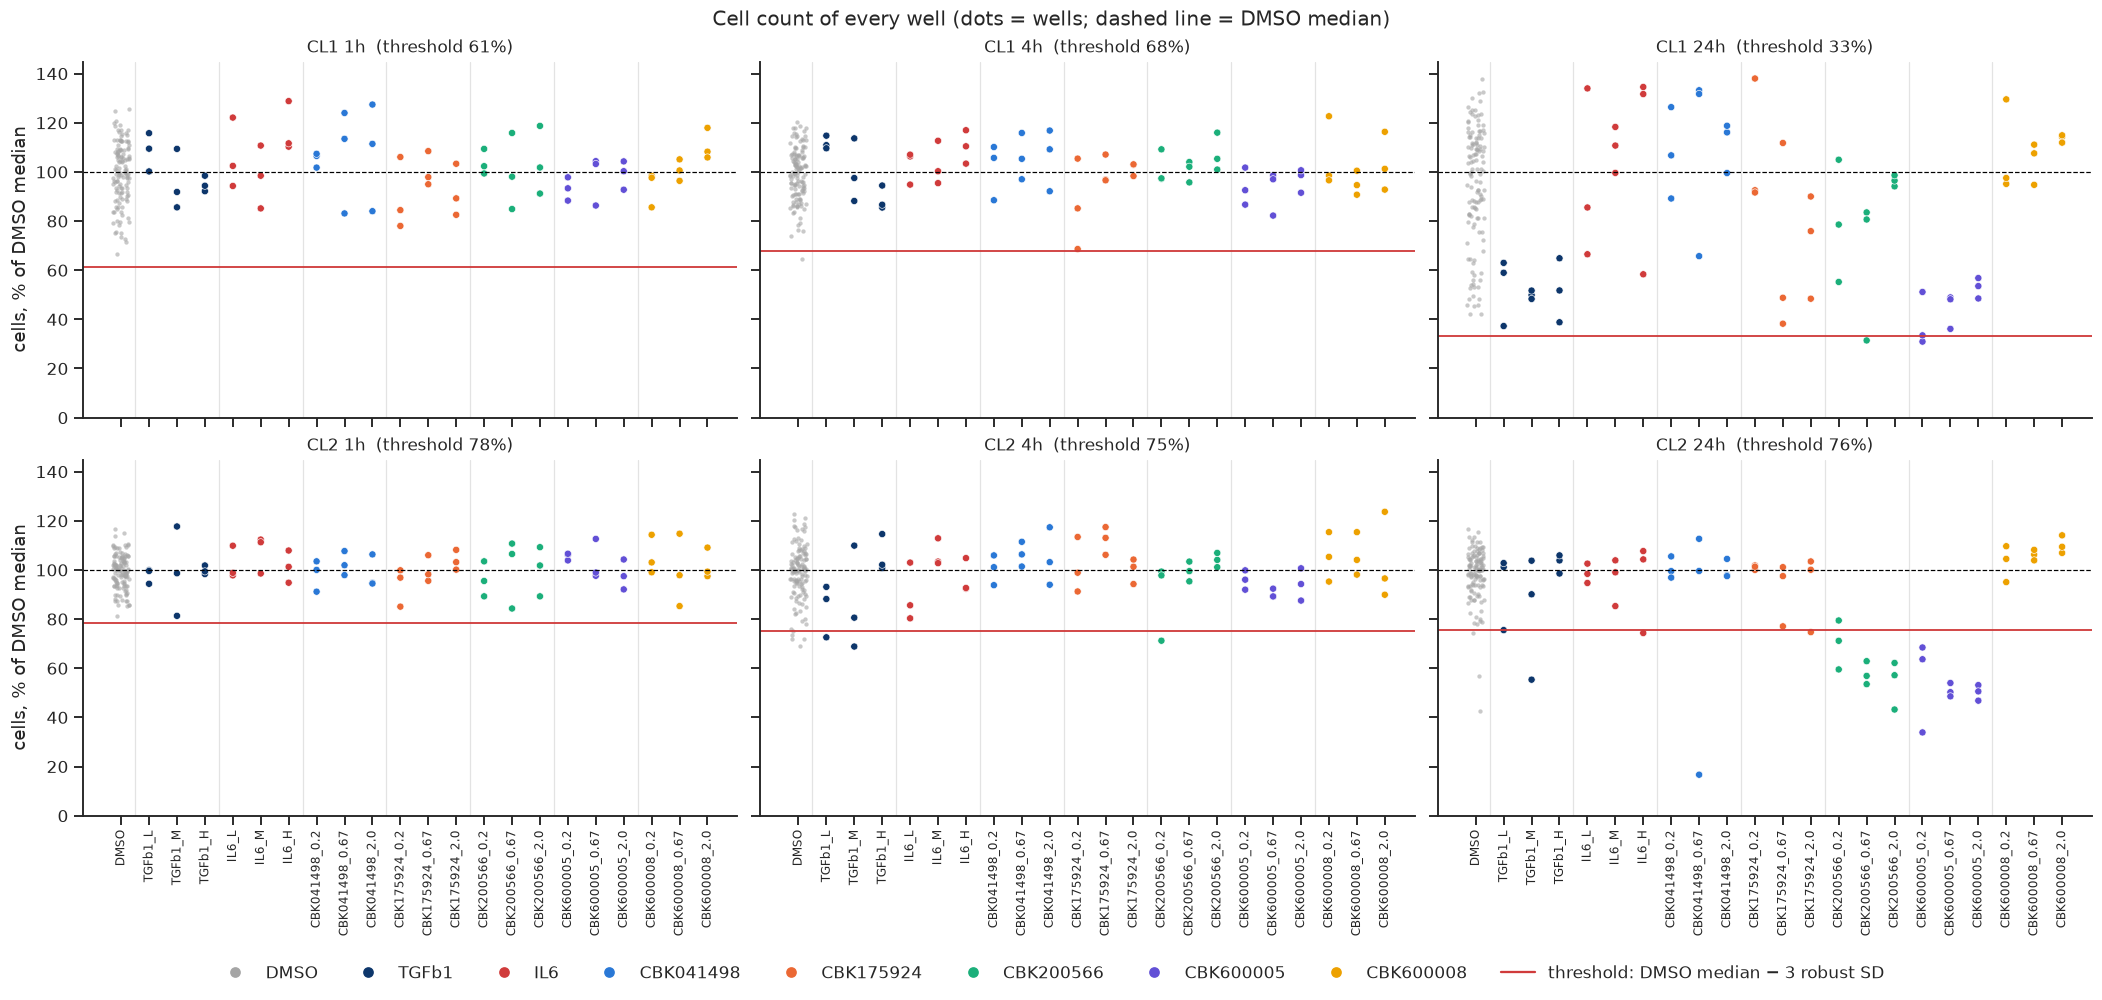

In [ ]:
# setting up the x-axis labels and positions for the scatter plot of cell counts for each well,
x_labels = ["DMSO", *perturbation_order]
x_pos = {p: i for i, p in enumerate(x_labels)}

# creating a new dataframe with x-axis positions and percentage of DMSO for each well, 
# and calculating the maximum y-value for the plot
plot_wells = wells.with_columns(
    x=pl.col("Metadata_Perturbation").replace_strict(x_pos, return_dtype=pl.Float64),
    pct=100 * pl.col("rel_count"),
)

# setting the maximum y-value for the scatter plot to be slightly above the maximum percentage of DMSO
y_max = float(plot_wells["pct"].max()) * 1.05

# setting figure and axes for the scatter plot of cell counts for each well, with shared x and y axes
fig, axes = plt.subplots(2, 3, figsize=(19, 8.5), layout="constrained", sharex=True, sharey=True)

# iterating over each cell line and time point, plotting the scatter plot of cell counts for each well,
for i, line in enumerate(line_order):
    for j, tp in enumerate(plate_order):
        ax = axes[i, j]
        sub = plot_wells.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp))
        dmso = sub.filter(pl.col("is_dmso"))
        jitter = rng.uniform(-0.3, 0.3, dmso.height)
        ax.scatter(dmso["x"] + jitter, dmso["pct"], s=8, color=agent_colors["DMSO"], alpha=0.6, linewidths=0)
        trt = sub.filter(~pl.col("is_dmso"))
        ax.scatter(trt["x"], trt["pct"], s=22, c=[agent_colors[t] for t in trt["treatment"]], edgecolor="white", linewidth=0.4)
        threshold = dmso_table.filter((pl.col("cell_line") == line) & (pl.col("time_point") == tp))["threshold_pct_of_dmso"][0]
        ax.axhline(100, color="black", lw=0.8, ls="--")
        ax.axhline(threshold, color="#d03b3b", lw=1.2)
        ax.set_title(f"{line} {tp}  (threshold {threshold:.0f}%)", fontsize=11)
        ax.set_ylim(0, y_max)
        for x in [0.5, 3.5, 6.5, 9.5, 12.5, 15.5, 18.5]:
            ax.axvline(x, color="#e3e3e3", lw=0.8, zorder=0)
    axes[i, 0].set_ylabel("cells, % of DMSO median")

# setting the x-ticks and labels for the bottom row of axes, adding a legend for the treatments and threshold line,
for ax in axes[1]:
    ax.set_xticks(range(len(x_labels)), labels=x_labels, rotation=90, fontsize=8)

# adding a legend for the treatments and threshold line, setting the super title for the figure, and saving the figure
handles = [Line2D([], [], marker="o", ls="", color=agent_colors[a], label=a) for a in ["DMSO", *treatment_order]]
handles.append(Line2D([], [], color="#d03b3b", label=f"threshold: DMSO median − {n_sd} robust SD"))

# adding legend and super title for the scatter plot of cell counts for each well, and saving the figure
fig.legend(handles=handles, loc="upper center", ncols=9, bbox_to_anchor=(0.5, -0.01), frameon=False)
fig.suptitle("Cell count of every well (dots = wells; dashed line = DMSO median)", fontsize=13)

# saving figure 
save_fig(fig, "02_cytotoxicity_replicate-wells")

- CL2 at 24h: the CBK200566 and CBK600005 wells sit as a group below or near the threshold, so the calls are not driven by one well. One CBK041498_0.67 well has only 17% of DMSO cells, but its 2 replicates are normal.
- CL1 at 24h: many DMSO wells have only 40–60% of the median, the same range as TGFβ1, CBK175924 and CBK600005. On this plate a cell loss cannot be told apart from the low-count area.

## Summary

**What we did:** counted all cells per well from the single-cell profiles, scaled each well to the DMSO median of its plate and cell line, and called a treatment cytotoxic when the median of its 3 wells is at least 3 robust SDs below DMSO. Random sets of 3 DMSO wells check the false-positive rate (at most 0.22% per test).

**Findings:**

- Cytotoxic: **CBK600005** and **CBK200566** in CL2 at 24h, at all 3 doses (50–71% of DMSO cells). There is no clear dose response: the 0.67 and 2 mM doses give the same loss.
- No treatment is cytotoxic at 1h or 4h.
- CL1 at 24h: CBK600005, TGFβ1 (M, H) and CBK175924_0.67 roughly halve the cell count but are not called, because the DMSO wells of this plate are too variable (threshold 33% of DMSO).

**Caveats:**

- Fewer cells can mean cell death or slower growth; a cell count cannot separate the two.
- Compound doses are stock concentrations; final concentrations are unknown.
- Cytotoxic treatments also change the profiles through cell density (see notebook 02), so their profile effects should be read with care.

**Outputs:** `tables/04.identify-cytotoxic-perts/cytotoxicity_calls.csv` (one row per treatment, plate and cell line) and `dmso_threshold.csv` (DMSO spread and threshold per plate and cell line).